# Simulación de proceso
## Simulación de Procesos Financieros

Ximena Muñoz

15/09/26

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
T = 1
r = 0.05
V = 0.20
S0 = 100
K = 110
n = 252
dt = T / n
M = 50

In [3]:
precios = [S0]

for i in range(n):

    Z = np.random.normal(0, 1)

    S_nuevo = precios[-1] * np.exp(
        (r - 0.5 * V**2) * dt
        + V * np.sqrt(dt) * Z
    )

    precios.append(S_nuevo)

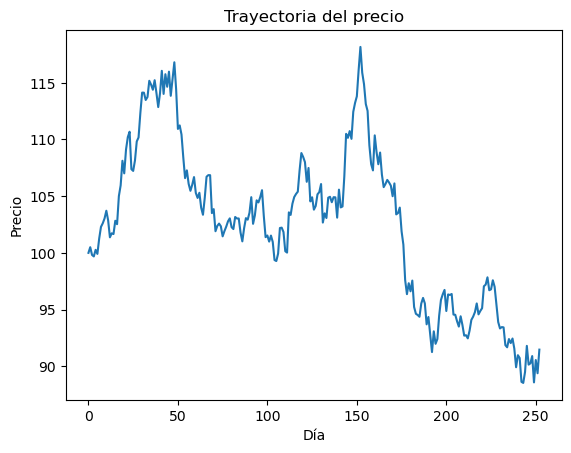

In [4]:
plt.plot(precios)

plt.xlabel("Día")
plt.ylabel("Precio")
plt.title("Trayectoria del precio")

plt.show()

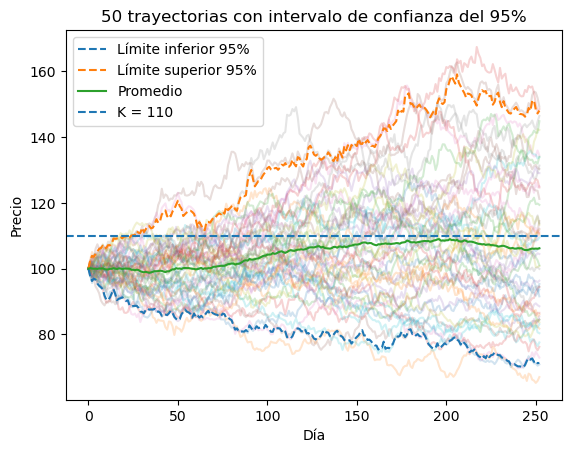

In [5]:
M = 50

trayectorias = []

for j in range(M):

    precios = [S0]

    for i in range(n):

        Z = np.random.normal(0, 1)

        S_nuevo = precios[-1] * np.exp(
            (r - 0.5 * V**2) * dt
            + V * np.sqrt(dt) * Z
        )

        precios.append(S_nuevo)

    trayectorias.append(precios)

P5 = np.percentile(trayectorias, 2.5, axis=0)
P95 = np.percentile(trayectorias, 97.5, axis=0)

media = np.mean(trayectorias, axis=0)

for trayectoria in trayectorias:
    plt.plot(trayectoria, alpha=0.2)

plt.plot(P5, linestyle="--", label="Límite inferior 95%")
plt.plot(P95, linestyle="--", label="Límite superior 95%")

plt.plot(media, label="Promedio")

plt.axhline(K, linestyle="--", label="K = 110")

plt.xlabel("Día")
plt.ylabel("Precio")
plt.title("50 trayectorias con intervalo de confianza del 95%")

plt.legend()
plt.show()

In [6]:
M = 1000

In [7]:
ST = []
S_promedio = []

payoff_europea = []
payoff_asiatica = []

for j in range(M):

    precios = [S0]

    for i in range(n):

        Z = np.random.normal(0, 1)

        S_nuevo = precios[-1] * np.exp(
            (r - 0.5 * V**2) * dt
            + V * np.sqrt(dt) * Z
        )

        precios.append(S_nuevo)

    ST.append(precios[-1])

    S_promedio.append(np.mean(precios[1:]))

    payoff_europea.append(max(precios[-1] - K, 0))

    payoff_asiatica.append(max(np.mean(precios[1:]) - K, 0))

In [8]:
promedio_trayectoria = np.mean(S_promedio)

print("Promedio de las trayectorias:", promedio_trayectoria)

Promedio de las trayectorias: 102.71999805522744


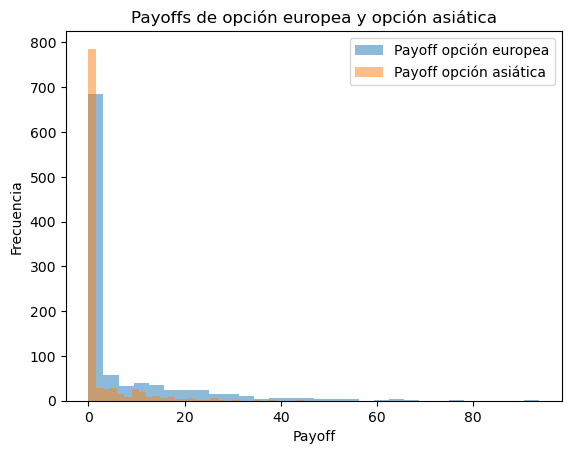

In [11]:
plt.hist(
    payoff_europea,
    bins=30,
    alpha=0.5,
    label="Payoff opción europea"
)

plt.hist(
    payoff_asiatica,
    bins=30,
    alpha=0.5,
    label="Payoff opción asiática"
)

plt.xlabel("Payoff")
plt.ylabel("Frecuencia")
plt.title("Payoffs de opción europea y opción asiática")

plt.legend()
plt.show()

In [12]:
precio_europea = np.exp(-r*T) * np.mean(payoff_europea)

print("Precio opción europea:", precio_europea)

Precio opción europea: 5.795532231572295


In [13]:
precio_asiatica = np.exp(-r*T) * np.mean(payoff_asiatica)

print("Precio opción asiática:", precio_asiatica)

Precio opción asiática: 2.0891964624481982


In [14]:
print("Precio opción europea:", precio_europea)
print("Precio opción asiática:", precio_asiatica)

print("Diferencia:", precio_europea - precio_asiatica)

Precio opción europea: 5.795532231572295
Precio opción asiática: 2.0891964624481982
Diferencia: 3.706335769124097


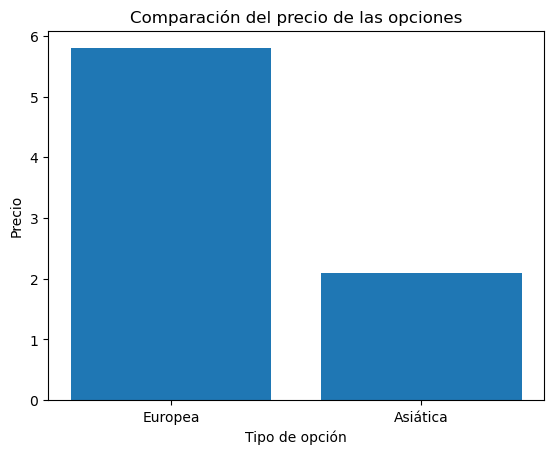

In [15]:
opciones = ["Europea", "Asiática"]
precios_opciones = [precio_europea, precio_asiatica]

plt.bar(opciones, precios_opciones)

plt.xlabel("Tipo de opción")
plt.ylabel("Precio")
plt.title("Comparación del precio de las opciones")

plt.show()